In [1]:
#Instalar a biblioteca para baixar a base
#Usaremos kagglehub, a biblioteca oficial do Kaggle para acessar datasets
!pip -q install kagglehub

In [2]:
#Importar as bibliotecas e baixar os dados
import kagglehub
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split

# Semente para reproduzir a divisão e os experimentos
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Download da base
caminho = Path(
    kagglehub.dataset_download(
        "puneet6060/intel-image-classification"
    )
)

print("Dados disponíveis em:", caminho)
print("TensorFlow:", tf.__version__)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dados disponíveis em: /kaggle/input/intel-image-classification
TensorFlow: 2.20.0


In [3]:
#Localizar as pastas e identificar as classes
classes = [
    "buildings",
    "forest",
    "glacier",
    "mountain",
    "sea",
    "street"
]

def localizar_pasta(nome):
    candidatas = [caminho / nome]
    candidatas += list(caminho.rglob(nome))

    for pasta in candidatas:
        if pasta.is_dir() and all(
            (pasta / classe).is_dir() for classe in classes
        ):
            return pasta

    raise FileNotFoundError(
        f"Não foi encontrada uma pasta {nome} com as seis classes."
    )

pasta_treino = localizar_pasta("seg_train")
pasta_teste = localizar_pasta("seg_test")

print("Pasta de treino:", pasta_treino)
print("Pasta de teste:", pasta_teste)

# Cada classe recebe um número
classe_para_indice = {
    classe: indice
    for indice, classe in enumerate(classes)
}

print("\nMapeamento das classes:")
print(classe_para_indice)

Pasta de treino: /kaggle/input/intel-image-classification/seg_train/seg_train
Pasta de teste: /kaggle/input/intel-image-classification/seg_test/seg_test

Mapeamento das classes:
{'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


In [4]:
#Criar a lista de imagens e separar treino e validação
def listar_imagens(pasta):
    registros = []

    for classe in classes:
        for arquivo in sorted((pasta / classe).iterdir()):
            if arquivo.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                registros.append({
                    "caminho": str(arquivo),
                    "classe": classe,
                    "rotulo": classe_para_indice[classe]
                })

    return pd.DataFrame(registros)

dados_treino_completo = listar_imagens(pasta_treino)
dados_teste = listar_imagens(pasta_teste)

dados_treino, dados_validacao = train_test_split(
    dados_treino_completo,
    test_size=0.20,
    random_state=SEED,
    stratify=dados_treino_completo["rotulo"]
)

# Reorganizar os índices das tabelas
dados_treino = dados_treino.reset_index(drop=True)
dados_validacao = dados_validacao.reset_index(drop=True)
dados_teste = dados_teste.reset_index(drop=True)

# Conferir a distribuição das classes
distribuicao = pd.DataFrame({
    "Treino": dados_treino["classe"].value_counts(),
    "Validação": dados_validacao["classe"].value_counts(),
    "Teste": dados_teste["classe"].value_counts()
}).reindex(classes)

display(distribuicao)

print("Total de treino:", len(dados_treino))
print("Total de validação:", len(dados_validacao))
print("Total de teste:", len(dados_teste))

,Treino,Validação,Teste
classe,,,
buildings,1753,438,437
forest,1817,454,474
glacier,1923,481,553
mountain,2009,503,525
sea,1819,455,510
street,1906,476,501


Total de treino: 11227
Total de validação: 2807
Total de teste: 3000


In [5]:
#Preparar as imagens para a CNN
TAMANHO_IMAGEM = (128, 128)
BATCH_SIZE = 32

def carregar_imagem(caminho_arquivo, rotulo):
    conteudo = tf.io.read_file(caminho_arquivo)

    imagem = tf.io.decode_image(
        conteudo,
        channels=3,
        expand_animations=False
    )

    imagem.set_shape([None, None, 3])

    imagem = tf.image.resize(
        imagem,
        TAMANHO_IMAGEM
    )

    imagem = tf.cast(imagem, tf.float32) / 255.0

    return imagem, rotulo


def criar_dataset(tabela, treinamento=False):
    caminhos = tabela["caminho"].to_numpy()
    rotulos = tabela["rotulo"].to_numpy(dtype="int32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (caminhos, rotulos)
    )

    # Apenas o treino é embaralhado a cada época
    if treinamento:
        dataset = dataset.shuffle(
            buffer_size=len(tabela),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        carregar_imagem,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


treino_ds = criar_dataset(
    dados_treino,
    treinamento=True
)

validacao_ds = criar_dataset(dados_validacao)
teste_ds = criar_dataset(dados_teste)

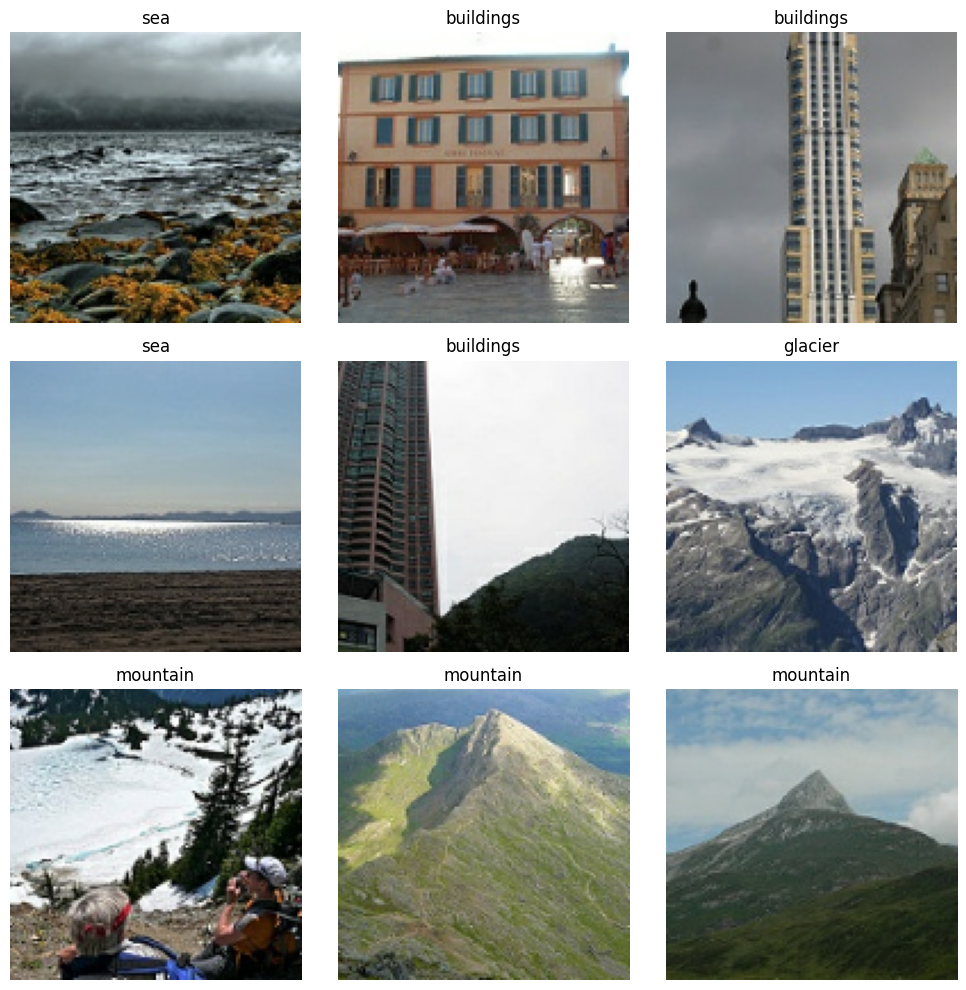

In [6]:
#Visualizar algumas imagens do treino
plt.figure(figsize=(10, 10))

for imagens, rotulos in treino_ds.take(1):
    for i in range(min(9, imagens.shape[0])):
        plt.subplot(3, 3, i + 1)

        plt.imshow(imagens[i].numpy())

        indice_classe = int(rotulos[i].numpy())
        plt.title(classes[indice_classe])

        plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
#Conferir o formato que a CNN receberá
for imagens, rotulos in treino_ds.take(1):
    print("Formato das imagens:", imagens.shape)
    print("Formato dos rótulos:", rotulos.shape)
    print("Rótulos:", rotulos.numpy())

    print("Menor valor dos pixels:", float(tf.reduce_min(imagens)))
    print("Maior valor dos pixels:", float(tf.reduce_max(imagens)))

Formato das imagens: (32, 128, 128, 3)
Formato dos rótulos: (32,)
Rótulos: [5 1 3 0 4 3 1 0 2 3 0 4 1 4 0 2 1 3 0 4 3 5 4 0 0 4 1 1 3 1 5 0]
Menor valor dos pixels: 0.0
Maior valor dos pixels: 1.0


In [9]:
#construir a CNN
from tensorflow import keras
from tensorflow.keras import layers

modelo_base = keras.Sequential([
    keras.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(6, activation="softmax")
])

modelo_base.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modelo_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,534 (431.77 KB)

 Trainable params: 110,534 (431.77 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Treinamento simples por 30 épocas
historico = modelo_base.fit(
    treino_ds,
    validation_data=validacao_ds,
    epochs=30
)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.8522 - loss: 0.4028 - val_accuracy: 0.8265 - val_loss: 0.4787
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.8570 - loss: 0.3984 - val_accuracy: 0.8215 - val_loss: 0.5287
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.8612 - loss: 0.3787 - val_accuracy: 0.8486 - val_loss: 0.4433
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.8645 - loss: 0.3706 - val_accuracy: 0.8379 - val_loss: 0.4546
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.8648 - loss: 0.3692 - val_accuracy: 0.8358 - val_loss: 0.4734
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8707 - loss: 0.3542 - val_accuracy: 0.8440 - val_loss: 0.4510
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.8779 - loss: 0.3318 - val_accuracy: 0.8318 - val_loss: 0.4870
Epoch 8/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.8786 - loss: 0.3295 - va

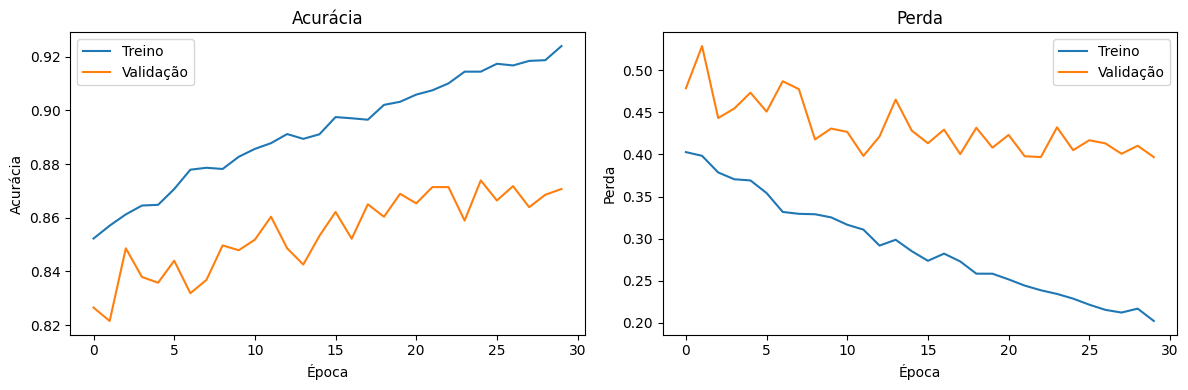

In [14]:
#visualizar as curvas de acurácia e perda
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(historico.history["accuracy"], label="Treino")
plt.plot(historico.history["val_accuracy"], label="Validação")
plt.title("Acurácia")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(historico.history["loss"], label="Treino")
plt.plot(historico.history["val_loss"], label="Validação")
plt.title("Perda")
plt.xlabel("Época")
plt.ylabel("Perda")
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
modelo_base.evaluate(validacao_ds)

88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.8707 - loss: 0.3969


[0.39688289165496826, 0.8706804513931274]

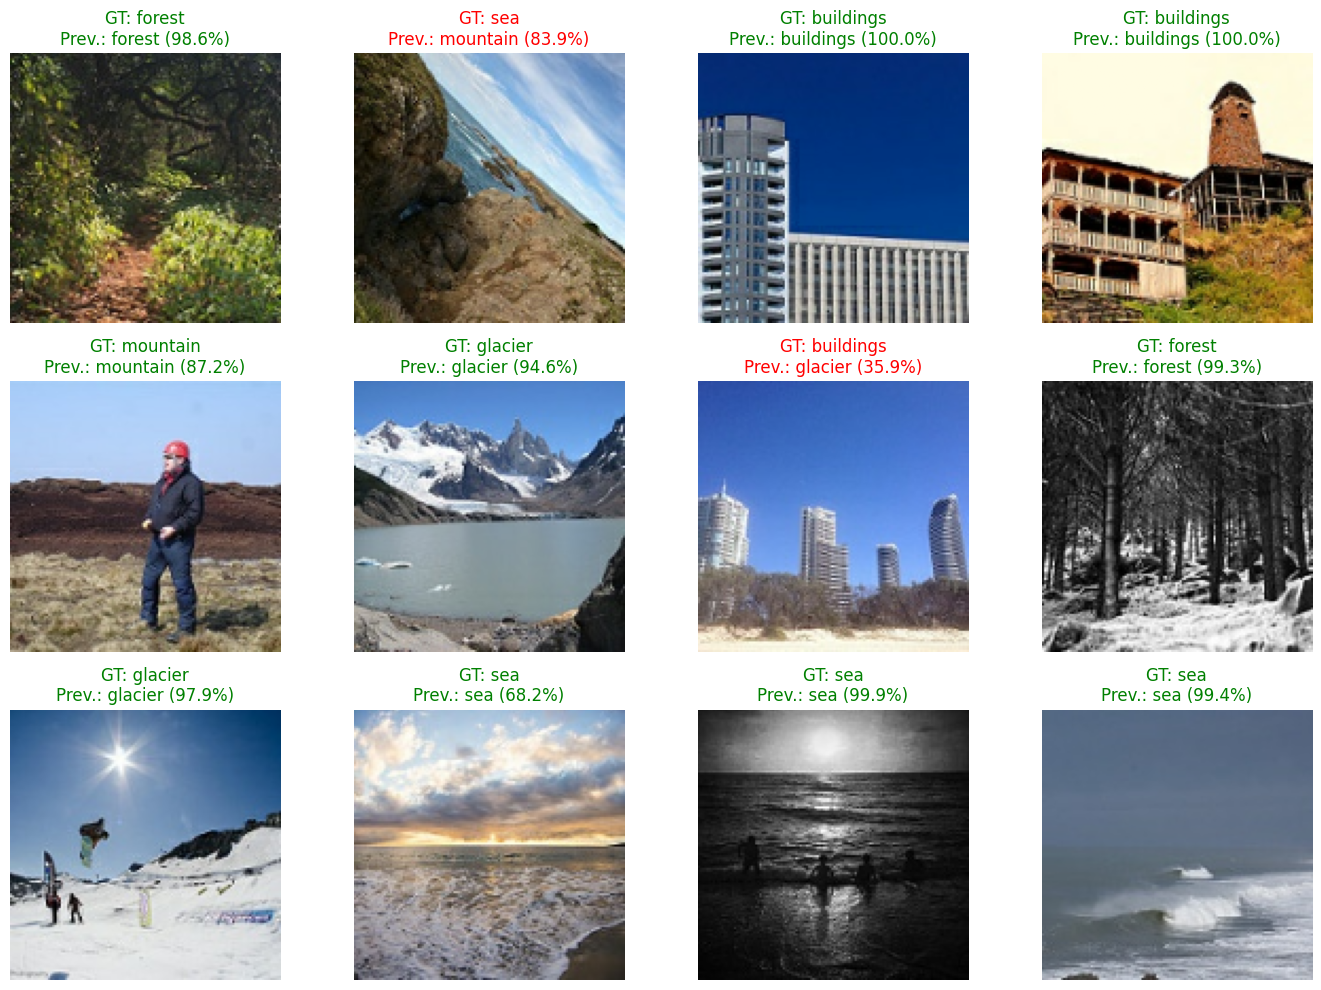

In [19]:
# Mostrando predições em imagens aleatórias da validação
import numpy as np
import matplotlib.pyplot as plt

quantidade = 12

imagens, rotulos_gt = next(
    iter(
        validacao_ds
        .unbatch()
        .shuffle(
            buffer_size=len(dados_validacao),
            reshuffle_each_iteration=True
        )
        .take(quantidade)
        .batch(quantidade)
    )
)

probabilidades = modelo_base.predict(imagens, verbose=0)
rotulos_previstos = np.argmax(probabilidades, axis=1)
confiancas = np.max(probabilidades, axis=1)

plt.figure(figsize=(14, 10))

for i in range(len(imagens)):
    gt = int(rotulos_gt[i].numpy())
    previsto = int(rotulos_previstos[i])
    confianca = confiancas[i]

    plt.subplot(3, 4, i + 1)
    plt.imshow(imagens[i].numpy())

    cor = "green" if gt == previsto else "red"

    plt.title(
        f"GT: {classes[gt]}\n"
        f"Prev.: {classes[previsto]} ({confianca:.1%})",
        color=cor
    )
    plt.axis("off")

plt.tight_layout()
plt.show()